> Repository edition: run from the repository root using an environment with the dependencies in `requirements.txt`. Machine-specific environment paths have been replaced. Historical outputs are retained except environment checks; they are not evidence of a fresh rerun. See `docs/REPRODUCIBILITY.md`.


# CP_23 — Round 12
## Black-box optimisation: structure, variance and redundancy

This notebook prepares one query for each of the eight black-box functions
using the initial observations and feedback from eleven completed rounds.

The workflow follows the previous notebooks:

1. Check the environment and validate the cumulative observations.
2. Review round-11 improvements and historical prediction errors.
3. Examine input variation, redundancy and projections using PCA.
4. Update the models and compare candidate queries.
5. Select and validate eight queries for round 12.

PCA will be used as an exploratory diagnostic for each function separately.
Directions explaining input variance are not automatically directions that
improve the objective. Any decision to simplify the search must therefore
also consider observed outputs and predictive performance.

The analysis will support planning for the final submission in Module 24.
Round-12 proposals and predictions will remain separate from observed
evaluations until portal feedback becomes available.

In [ ]:
# CP_23 — Round 12
# Check the Python environment and locate the project data.

import sys
from pathlib import Path

project_path = Path.cwd()

# Use the selected notebook kernel; no machine-specific path is required.
expected_python = Path(sys.executable)

initial_data_path = project_path / "initial_data"
feedback_path = project_path / "week_11"

inputs_path = feedback_path / "inputs.txt"
outputs_path = feedback_path / "outputs.txt"

# Expected round numbers; file contents will be validated next.
completed_rounds = 11
submission_round = 12

correct_kernel = (
    Path(sys.executable).resolve() == expected_python.resolve()
)

print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())
print("Project folder:", project_path)

print("\nSelected interpreter check:", correct_kernel)
print("Project folder found:", project_path.is_dir())
print("Initial data folder found:", initial_data_path.is_dir())
print("Feedback folder found:", feedback_path.is_dir())
print("Cumulative inputs found:", inputs_path.is_file())
print("Cumulative outputs found:", outputs_path.is_file())

print("\nExpected completed rounds:", completed_rounds)
print("Round to prepare:", submission_round)

assert correct_kernel, (
    "Select the notebook kernel corresponding to: "
    f"{expected_python}"
)
assert project_path.is_dir(), (
    f"Project folder not found: {project_path}"
)
assert initial_data_path.is_dir(), (
    f"Initial data folder not found: {initial_data_path}"
)
assert feedback_path.is_dir(), (
    f"Feedback folder not found: {feedback_path}"
)
assert inputs_path.is_file(), (
    f"Inputs file not found: {inputs_path}"
)
assert outputs_path.is_file(), (
    f"Outputs file not found: {outputs_path}"
)

# Import project dependencies after checking the selected environment.
import numpy as np
import pandas as pd
from IPython.display import display

print("\nEnvironment and file checks passed.")
print(
    f"Ready to load and validate the {completed_rounds} feedback rounds."
)

## 2. Load and validate the cumulative observations

The initial observations are combined with eleven completed feedback
rounds for each function. Each round must contain one query and one
observed output for each of the eight functions.

Validation checks the number of rounds, input dimensions, finite
numerical values and input bounds. Negative and extremely small outputs
are retained.

The cumulative feedback files are loaded once; earlier weekly snapshots
are not appended again, which avoids counting the same evaluations twice.

In [2]:
# Load the initial observations and eleven cumulative feedback rounds.

import ast
import numpy as np

required_variables = [
    "initial_data_path",
    "inputs_path",
    "outputs_path",
    "completed_rounds",
    "submission_round",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the first code cell before this cell. "
        f"Missing variables: {', '.join(missing_variables)}"
    )


class ArrayLiteralTransformer(ast.NodeTransformer):
    """Convert array([...]) wrappers into literal lists without executing code."""

    def visit_Call(self, node):
        is_array = (
            isinstance(node.func, ast.Name)
            and node.func.id == "array"
        )
        is_numpy_array = (
            isinstance(node.func, ast.Attribute)
            and isinstance(node.func.value, ast.Name)
            and node.func.value.id in {"np", "numpy"}
            and node.func.attr == "array"
        )

        if not (is_array or is_numpy_array):
            raise ValueError("Unsupported function call in feedback file.")

        if len(node.args) != 1 or node.keywords:
            raise ValueError(
                "Expected an array wrapper with one argument and no keywords."
            )

        return self.visit(node.args[0])


def read_feedback_rounds(path):
    """Read successive literal round lists safely, without eval()."""
    text = path.read_text(encoding="utf-8-sig").strip()

    if not text:
        raise ValueError(f"Feedback file is empty: {path}")

    tree = ast.parse(text, mode="exec")
    rounds = []

    for statement in tree.body:
        if not isinstance(statement, ast.Expr):
            raise ValueError(
                f"Expected literal round lists only in: {path.name}"
            )

        literal = ArrayLiteralTransformer().visit(statement.value)
        round_values = ast.literal_eval(literal)

        if not isinstance(round_values, (list, tuple)):
            raise ValueError(
                f"Each round must be a list or tuple in: {path.name}"
            )

        rounds.append(round_values)

    return rounds


function_dimensions = {
    1: 2,
    2: 2,
    3: 3,
    4: 4,
    5: 4,
    6: 5,
    7: 6,
    8: 8,
}

expected_initial_counts = {
    1: 10,
    2: 10,
    3: 15,
    4: 30,
    5: 20,
    6: 20,
    7: 30,
    8: 40,
}

input_rounds = read_feedback_rounds(inputs_path)
output_rounds = read_feedback_rounds(outputs_path)

assert len(input_rounds) == completed_rounds, (
    f"Expected {completed_rounds} input rounds; "
    f"found {len(input_rounds)}."
)
assert len(output_rounds) == completed_rounds, (
    f"Expected {completed_rounds} output rounds; "
    f"found {len(output_rounds)}."
)

for round_number, (round_inputs, round_outputs) in enumerate(
    zip(input_rounds, output_rounds), start=1
):
    assert len(round_inputs) == 8, (
        f"Round {round_number}: expected inputs for eight functions."
    )
    assert len(round_outputs) == 8, (
        f"Round {round_number}: expected outputs for eight functions."
    )

initial_data = {}
feedback_data = {}
updated_data = {}

for function_id in range(1, 9):
    dimensions = function_dimensions[function_id]
    initial_count = expected_initial_counts[function_id]

    function_path = initial_data_path / f"function_{function_id}"
    initial_inputs_file = function_path / "initial_inputs.npy"
    initial_outputs_file = function_path / "initial_outputs.npy"

    assert initial_inputs_file.is_file(), (
        f"Initial inputs not found: {initial_inputs_file}"
    )
    assert initial_outputs_file.is_file(), (
        f"Initial outputs not found: {initial_outputs_file}"
    )

    X_initial = np.asarray(
        np.load(initial_inputs_file, allow_pickle=False),
        dtype=float,
    )
    y_initial = np.asarray(
        np.load(initial_outputs_file, allow_pickle=False),
        dtype=float,
    ).reshape(-1)

    assert X_initial.shape == (initial_count, dimensions), (
        f"Function {function_id}: unexpected initial input shape "
        f"{X_initial.shape}."
    )
    assert y_initial.shape == (initial_count,), (
        f"Function {function_id}: unexpected initial output shape "
        f"{y_initial.shape}."
    )

    feedback_inputs = []
    feedback_outputs = []

    for round_index in range(completed_rounds):
        query = np.asarray(
            input_rounds[round_index][function_id - 1],
            dtype=float,
        )
        output = np.asarray(
            output_rounds[round_index][function_id - 1],
            dtype=float,
        )

        assert query.shape == (dimensions,), (
            f"Function {function_id}, round {round_index + 1}: "
            f"expected {dimensions} coordinates; found shape {query.shape}."
        )
        assert output.size == 1, (
            f"Function {function_id}, round {round_index + 1}: "
            "expected one scalar output."
        )

        feedback_inputs.append(query)
        feedback_outputs.append(output.item())

    X_feedback = np.asarray(feedback_inputs, dtype=float)
    y_feedback = np.asarray(feedback_outputs, dtype=float)

    X = np.vstack([X_initial, X_feedback])
    y = np.concatenate([y_initial, y_feedback])

    assert np.isfinite(X).all(), (
        f"Function {function_id}: non-finite input values."
    )
    assert np.isfinite(y).all(), (
        f"Function {function_id}: non-finite output values."
    )
    assert ((X >= 0.0) & (X <= 1.0)).all(), (
        f"Function {function_id}: input coordinates outside [0, 1]."
    )
    assert X.shape == (initial_count + completed_rounds, dimensions)
    assert y.shape == (initial_count + completed_rounds,)

    initial_data[function_id] = {
        "X": X_initial,
        "y": y_initial,
    }
    feedback_data[function_id] = {
        "X": X_feedback,
        "y": y_feedback,
    }
    updated_data[function_id] = {
        "X": X,
        "y": y,
    }

    print(
        f"Function {function_id}: "
        f"{initial_count} → {len(y)} observations | "
        f"{dimensions} variables"
    )

total_observations = sum(
    len(data["y"]) for data in updated_data.values()
)

print("\nValidated feedback rounds:", len(input_rounds))
print("Round to prepare:", submission_round)
print("Total evaluated observations:", total_observations)
print("All eight datasets loaded and validated successfully.")

Function 1: 10 → 21 observations | 2 variables
Function 2: 10 → 21 observations | 2 variables
Function 3: 15 → 26 observations | 3 variables
Function 4: 30 → 41 observations | 4 variables
Function 5: 20 → 31 observations | 4 variables
Function 6: 20 → 31 observations | 5 variables
Function 7: 30 → 41 observations | 6 variables
Function 8: 40 → 51 observations | 8 variables

Validated feedback rounds: 11
Round to prepare: 12
Total evaluated observations: 263
All eight datasets loaded and validated successfully.


## 3. Review observed improvements through round 11

For each function, the latest observed output is compared with the best
value available before round 11. All functions are treated as
maximisation problems, including those with negative outputs.

The improvement history tracks when a new observation exceeded the
previous best. An unsuccessful query remains part of the training data:
it can inform the model even when it does not improve the best result.

These comparisons use observed evaluations only. Predictions and
acquisition scores are not counted as achieved improvements.

In [3]:
# Review observed improvements across all completed rounds.

import numpy as np
import pandas as pd
from IPython.display import display

required_variables = [
    "initial_data",
    "feedback_data",
    "updated_data",
    "completed_rounds",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding code cells before this cell. "
        f"Missing variables: {', '.join(missing_variables)}"
    )

history_records = []

for function_id in range(1, 9):
    initial_outputs = initial_data[function_id]["y"]
    feedback_outputs = feedback_data[function_id]["y"]

    assert len(feedback_outputs) == completed_rounds, (
        f"Function {function_id}: unexpected number of feedback outputs."
    )

    best_so_far = float(np.max(initial_outputs))

    for round_number, observed_output in enumerate(
        feedback_outputs, start=1
    ):
        observed_output = float(observed_output)
        previous_best = best_so_far
        improved = observed_output > previous_best
        improvement = max(0.0, observed_output - previous_best)
        best_so_far = max(previous_best, observed_output)

        history_records.append({
            "Function": function_id,
            "Round": round_number,
            "Best before round": previous_best,
            "Observed output": observed_output,
            "Improved": improved,
            "Improvement": improvement,
            "Best so far": best_so_far,
        })

    assert best_so_far == float(
        np.max(updated_data[function_id]["y"])
    ), (
        f"Function {function_id}: inconsistent best observed output."
    )

improvement_history_df = pd.DataFrame(history_records)

round_comparison_df = (
    improvement_history_df.loc[
        improvement_history_df["Round"] == completed_rounds
    ]
    .drop(columns="Round")
    .rename(columns={
        "Best before round": f"Best before round {completed_rounds}",
        "Observed output": f"Round {completed_rounds} output",
        "Improved": f"Round {completed_rounds} improved",
        "Best so far": "Current best",
    })
    .set_index("Function")
    .sort_index()
)

numeric_columns = [
    f"Best before round {completed_rounds}",
    f"Round {completed_rounds} output",
    "Improvement",
    "Current best",
]

display(
    round_comparison_df.style.format({
        column: "{:.6e}" for column in numeric_columns
    })
)

for round_number in range(1, completed_rounds + 1):
    improved_functions = (
        improvement_history_df.loc[
            (improvement_history_df["Round"] == round_number)
            & improvement_history_df["Improved"],
            "Function",
        ]
        .sort_values()
        .tolist()
    )

    print(
        f"Functions improved in round {round_number}: "
        f"{improved_functions} | Count: {len(improved_functions)}"
    )

print(
    "\nImprovements are calculated from observed outputs, "
    "not model predictions."
)

,Best before round 11,Round 11 output,Round 11 improved,Improvement,Current best
Function,,,,,
1,7.710875e-16,-8.542963e-119,False,0.000000e+00,7.710875e-16
2,6.582395e-01,5.371003e-01,False,0.000000e+00,6.582395e-01
3,-3.096391e-02,-1.949330e-01,False,0.000000e+00,-3.096391e-02
4,6.152729e-01,5.059967e-01,False,0.000000e+00,6.152729e-01
5,8.515379e+03,8.311706e+03,False,0.000000e+00,8.515379e+03
6,-2.424310e-01,-3.615947e-01,False,0.000000e+00,-2.424310e-01
7,2.436323e+00,2.351393e+00,False,0.000000e+00,2.436323e+00
8,9.958227e+00,9.899580e+00,False,0.000000e+00,9.958227e+00


Functions improved in round 1: [2, 4, 5, 7, 8] | Count: 5
Functions improved in round 2: [6, 8] | Count: 2
Functions improved in round 3: [5, 8] | Count: 2
Functions improved in round 4: [6, 8] | Count: 2
Functions improved in round 5: [3, 4, 5, 8] | Count: 4
Functions improved in round 6: [5, 6, 7] | Count: 3
Functions improved in round 7: [5] | Count: 1
Functions improved in round 8: [4, 5, 7] | Count: 3
Functions improved in round 9: [8] | Count: 1
Functions improved in round 10: [5, 7] | Count: 2
Functions improved in round 11: [] | Count: 0

Improvements are calculated from observed outputs, not model predictions.


## 4. Compare round-11 predictions with observed outputs

None of the eight round-11 queries improved the previous best observed
output. These evaluations are nevertheless retained when updating the
models.

The predictions recorded in CP_22 are compared with the corresponding
observed outputs. Historical query coordinates are checked against the
feedback inputs before calculating errors.

Absolute error divided by predicted standard deviation is reported as
an observation-level diagnostic, not as a complete uncertainty
calibration assessment. Historical predictions are rounded, so the
calculated errors are approximate.

For Function 5, the evaluated query was the distance-constrained
alternative. Its result does not reveal what the unsubmitted standard
proposal would have achieved.

In [5]:
# Compare historical CP_22 predictions with round-11 feedback.

import numpy as np
import pandas as pd
from IPython.display import display

required_variables = [
    "feedback_data",
    "function_dimensions",
    "completed_rounds",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding code cells before this cell. "
        f"Missing variables: {', '.join(missing_variables)}"
    )

historical_round = 11

assert completed_rounds == historical_round, (
    "This cell compares CP_22 predictions with round-11 feedback."
)

# Rounded predictions recorded before the round-11 evaluations.
# Function 5 uses the selected distance-constrained proposal.
historical_predictions = {
    1: {
        "query": "0.997786-0.810962",
        "mean": -1.043251e-04,
        "std": 7.300194e-04,
        "auxiliary": np.nan,
    },
    2: {
        "query": "0.690168-0.000257",
        "mean": 5.721264e-01,
        "std": 7.818321e-02,
        "auxiliary": np.nan,
    },
    3: {
        "query": "0.989378-0.010523-0.715547",
        "mean": -8.934356e-02,
        "std": 6.852852e-02,
        "auxiliary": np.nan,
    },
    4: {
        "query": "0.403515-0.409981-0.384203-0.416426",
        "mean": 4.052177e-01,
        "std": 2.003610e-01,
        "auxiliary": np.nan,
    },
    5: {
        "query": "0.998659-0.983879-0.999338-0.999448",
        "mean": 8.135976e+03,
        "std": 3.014681e+02,
        "auxiliary": 8.102115e+03,
    },
    6: {
        "query": "0.455442-0.366608-0.556940-0.676688-0.001142",
        "mean": -3.607229e-01,
        "std": 1.027307e-01,
        "auxiliary": np.nan,
    },
    7: {
        "query": (
            "0.003443-0.196129-0.472527-"
            "0.128049-0.314261-0.673736"
        ),
        "mean": 2.388085e+00,
        "std": 9.284172e-02,
        "auxiliary": 1.206557e+00,
    },
    8: {
        "query": (
            "0.009105-0.098331-0.085665-0.149083-"
            "0.983758-0.543950-0.329628-0.121389"
        ),
        "mean": 9.902413e+00,
        "std": 4.844239e-02,
        "auxiliary": np.nan,
    },
}

prediction_error_records = []

for function_id in range(1, 9):
    historical = historical_predictions[function_id]

    historical_query = np.array(
        [float(value) for value in historical["query"].split("-")],
        dtype=float,
    )

    actual_query = np.asarray(
        feedback_data[function_id]["X"][historical_round - 1],
        dtype=float,
    )

    assert historical_query.shape == (
        function_dimensions[function_id],
    ), (
        f"Function {function_id}: unexpected historical query dimensions."
    )

    assert np.allclose(
        historical_query,
        actual_query,
        rtol=0.0,
        atol=5e-7,
    ), (
        f"Function {function_id}: historical query does not match "
        f"round-{historical_round} feedback inputs."
    )

    observed_output = float(
        feedback_data[function_id]["y"][historical_round - 1]
    )
    predicted_mean = float(historical["mean"])
    predicted_std = float(historical["std"])
    auxiliary_prediction = float(historical["auxiliary"])

    assert np.isfinite(predicted_mean)
    assert np.isfinite(predicted_std) and predicted_std > 0.0
    assert np.isfinite(observed_output)

    signed_error = observed_output - predicted_mean
    absolute_error = abs(signed_error)

    auxiliary_absolute_error = (
        abs(observed_output - auxiliary_prediction)
        if np.isfinite(auxiliary_prediction)
        else np.nan
    )

    prediction_error_records.append({
        "Function": function_id,
        "Predicted mean": predicted_mean,
        "Predicted std": predicted_std,
        "Observed output": observed_output,
        "Observed minus predicted": signed_error,
        "Absolute error / predicted std": (
            absolute_error / predicted_std
        ),
        "GP absolute error": absolute_error,
        "Auxiliary prediction": auxiliary_prediction,
        "Auxiliary absolute error": auxiliary_absolute_error,
    })

prediction_errors_df = (
    pd.DataFrame(prediction_error_records)
    .set_index("Function")
    .sort_index()
)

error_formatters = {
    column: "{:.6e}"
    for column in prediction_errors_df.columns
}
error_formatters["Absolute error / predicted std"] = "{:.2f}"

display(
    prediction_errors_df.style.format(
        error_formatters,
        na_rep="—",
    )
)

print(
    f"\nAll eight historical queries match the round "
    f"{historical_round} feedback inputs."
)
print("Errors use rounded historical predictions from CP_22.")
print(
    "Error / predicted std is a diagnostic for these individual "
    "observations, not a complete uncertainty calibration assessment."
)

,Predicted mean,Predicted std,Observed output,Observed minus predicted,Absolute error / predicted std,GP absolute error,Auxiliary prediction,Auxiliary absolute error
Function,,,,,,,,
1,-1.043251e-04,7.300194e-04,-8.542963e-119,1.043251e-04,0.14,1.043251e-04,—,—
2,5.721264e-01,7.818321e-02,5.371003e-01,-3.502611e-02,0.45,3.502611e-02,—,—
3,-8.934356e-02,6.852852e-02,-1.949330e-01,-1.055894e-01,1.54,1.055894e-01,—,—
4,4.052177e-01,2.003610e-01,5.059967e-01,1.007790e-01,0.50,1.007790e-01,—,—
5,8.135976e+03,3.014681e+02,8.311706e+03,1.757296e+02,0.58,1.757296e+02,8.102115e+03,2.095906e+02
6,-3.607229e-01,1.027307e-01,-3.615947e-01,-8.717849e-04,0.01,8.717849e-04,—,—
7,2.388085e+00,9.284172e-02,2.351393e+00,-3.669236e-02,0.40,3.669236e-02,1.206557e+00,1.144836e+00
8,9.902413e+00,4.844239e-02,9.899580e+00,-2.832895e-03,0.06,2.832895e-03,—,—



All eight historical queries match the round 11 feedback inputs.
Errors use rounded historical predictions from CP_22.
Error / predicted std is a diagnostic for these individual observations, not a complete uncertainty calibration assessment.


## 5. Explore input variation with PCA

PCA is fitted separately to each function's observed input coordinates.
Outputs are excluded from fitting: the components describe variation
in sampled inputs, not directions that necessarily improve the objective.

All coordinates share the permitted [0, 1] range. The primary analysis
therefore centres inputs without rescaling their individual variances.
A standardised PCA is also calculated as a sensitivity comparison,
giving each non-constant coordinate equal variance before fitting.

The analysis reports explained variance, the number of components
needed to retain at least 90% of input variance, and the coordinate
weights of the first two components.

These results reflect the adaptively sampled history. Low input
variance may indicate concentrated sampling rather than an irrelevant
variable. No coordinates are removed from the optimisation models
based on this analysis.

In [6]:
# Explore sampled input variation using PCA for each function.

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display

required_variables = [
    "updated_data",
    "function_dimensions",
    "expected_initial_counts",
    "completed_rounds",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding code cells before this cell. "
        f"Missing variables: {', '.join(missing_variables)}"
    )

pca_diagnostics = {}
pca_summary_records = []
pca_variance_records = []
pca_weight_records = []
input_variation_records = []

variance_target = 0.90

for function_id in range(1, 9):
    X = np.asarray(updated_data[function_id]["X"], dtype=float)
    y = np.asarray(updated_data[function_id]["y"], dtype=float)
    dimensions = function_dimensions[function_id]

    assert X.shape[1] == dimensions
    assert len(X) == len(y)
    assert np.isfinite(X).all()
    assert np.isfinite(y).all()

    input_variances = np.var(X, axis=0, ddof=1)

    if input_variances.sum() <= 0.0:
        raise ValueError(
            f"Function {function_id}: PCA requires variation in inputs."
        )

    # Primary PCA: centre inputs, preserving their original relative variance.
    centred_pca = PCA(
        n_components=dimensions,
        svd_solver="full",
    )
    centred_scores = centred_pca.fit_transform(X)

    # Sensitivity comparison: standardise each coordinate before PCA.
    scaler = StandardScaler()
    X_standardised = scaler.fit_transform(X)

    standardised_pca = PCA(
        n_components=dimensions,
        svd_solver="full",
    )
    standardised_scores = standardised_pca.fit_transform(
        X_standardised
    )

    explained = centred_pca.explained_variance_ratio_
    cumulative = np.cumsum(explained)

    standardised_explained = (
        standardised_pca.explained_variance_ratio_
    )
    standardised_cumulative = np.cumsum(standardised_explained)

    components_90 = int(
        np.searchsorted(cumulative, variance_target) + 1
    )
    standardised_components_90 = int(
        np.searchsorted(
            standardised_cumulative,
            variance_target,
        ) + 1
    )

    initial_count = expected_initial_counts[function_id]
    observation_rounds = np.concatenate([
        np.zeros(initial_count, dtype=int),
        np.arange(1, completed_rounds + 1),
    ])

    assert len(observation_rounds) == len(X)

    pca_diagnostics[function_id] = {
        "centred_model": centred_pca,
        "centred_scores": centred_scores,
        "standardised_model": standardised_pca,
        "standardised_scores": standardised_scores,
        "scaler": scaler,
        "explained_variance_ratio": explained,
        "cumulative_explained_variance": cumulative,
        "components_for_90_percent": components_90,
        "observation_rounds": observation_rounds,
        "outputs": y.copy(),
    }

    pca_summary_records.append({
        "Function": function_id,
        "Observations": len(X),
        "Dimensions": dimensions,
        "PC1 explained variance": explained[0],
        "PC2 explained variance": explained[1],
        "PC1 + PC2 explained variance": cumulative[1],
        "Components for 90%": components_90,
        "Standardised PC1 + PC2": standardised_cumulative[1],
        "Standardised components for 90%": (
            standardised_components_90
        ),
    })

    for component_index in range(dimensions):
        pca_variance_records.append({
            "Function": function_id,
            "Component": f"PC{component_index + 1}",
            "Explained variance": explained[component_index],
            "Cumulative explained variance": (
                cumulative[component_index]
            ),
            "Standardised explained variance": (
                standardised_explained[component_index]
            ),
        })

    # Component weights are eigenvector coefficients, not output importance.
    for coordinate_index in range(dimensions):
        coordinate_name = f"x{coordinate_index + 1}"

        pca_weight_records.append({
            "Function": function_id,
            "Coordinate": coordinate_name,
            "PC1 weight": centred_pca.components_[
                0, coordinate_index
            ],
            "PC2 weight": centred_pca.components_[
                1, coordinate_index
            ],
        })

        input_variation_records.append({
            "Function": function_id,
            "Coordinate": coordinate_name,
            "Input mean": np.mean(X[:, coordinate_index]),
            "Input std": np.std(
                X[:, coordinate_index],
                ddof=1,
            ),
            "Input minimum": np.min(X[:, coordinate_index]),
            "Input maximum": np.max(X[:, coordinate_index]),
        })

pca_summary_df = (
    pd.DataFrame(pca_summary_records)
    .set_index("Function")
    .sort_index()
)

pca_variance_df = (
    pd.DataFrame(pca_variance_records)
    .set_index(["Function", "Component"])
)

pca_weights_df = (
    pd.DataFrame(pca_weight_records)
    .set_index(["Function", "Coordinate"])
)

input_variation_df = (
    pd.DataFrame(input_variation_records)
    .set_index(["Function", "Coordinate"])
)

print("PCA summary — input coordinates only")

display(
    pca_summary_df.style.format({
        "PC1 explained variance": "{:.1%}",
        "PC2 explained variance": "{:.1%}",
        "PC1 + PC2 explained variance": "{:.1%}",
        "Standardised PC1 + PC2": "{:.1%}",
    })
)

print("\nCoordinate weights in the first two centred components")

display(
    pca_weights_df.style.format("{:.4f}")
)

print("\nObserved variation of each input coordinate")

display(
    input_variation_df.style.format("{:.4f}")
)

print("\nPCA fitted separately for all eight functions.")
print("Observed outputs were not used to fit PCA.")
print(
    "Component weights describe input variation, "
    "not causal effects or predictive importance."
)
print(
    "Component signs are arbitrary; reversing a component's "
    "weights and scores does not change its interpretation."
)
print("All original coordinates remain available for optimisation.")

PCA summary — input coordinates only


,Observations,Dimensions,PC1 explained variance,PC2 explained variance,PC1 + PC2 explained variance,Components for 90%,Standardised PC1 + PC2,Standardised components for 90%
Function,,,,,,,,
1,21,2,68.4%,31.6%,100.0%,2,100.0%,2
2,21,2,72.5%,27.5%,100.0%,2,100.0%,2
3,26,3,52.8%,24.7%,77.5%,3,79.1%,3
4,41,4,38.6%,27.3%,65.9%,4,66.5%,4
5,31,4,55.1%,17.6%,72.7%,4,72.6%,4
6,31,5,40.6%,24.3%,64.9%,4,62.7%,4
7,41,6,34.6%,20.5%,55.1%,5,54.7%,5
8,51,8,31.5%,15.4%,47.0%,7,45.7%,7



Coordinate weights in the first two centred components



Observed variation of each input coordinate



PCA fitted separately for all eight functions.
Observed outputs were not used to fit PCA.
Component weights describe input variation, not causal effects or predictive importance.
Component signs are arbitrary; reversing a component's weights and scores does not change its interpretation.
All original coordinates remain available for optimisation.


## 6. Visualise PCA projections and explained variance

The first figure compares cumulative explained input variance for
centred and standardised PCA.

The second figure projects observations onto the first two centred
components. Colours represent within-function output ranks: higher
ranks indicate better observed results. Ranks help display patterns
across different output scales but hide the magnitude of differences.

Initial observations and sequential evaluations use different markers.
The best observed point and the latest evaluation are highlighted.
Outputs are used for annotation only; they were excluded from PCA fitting.

These projections describe the sampled history. Apparent groupings
may reflect adaptive sampling, and proximity in two dimensions does
not guarantee proximity in the original search space. This limitation
is especially relevant to Function 8, where the first two components
retain approximately 47% of input variance.

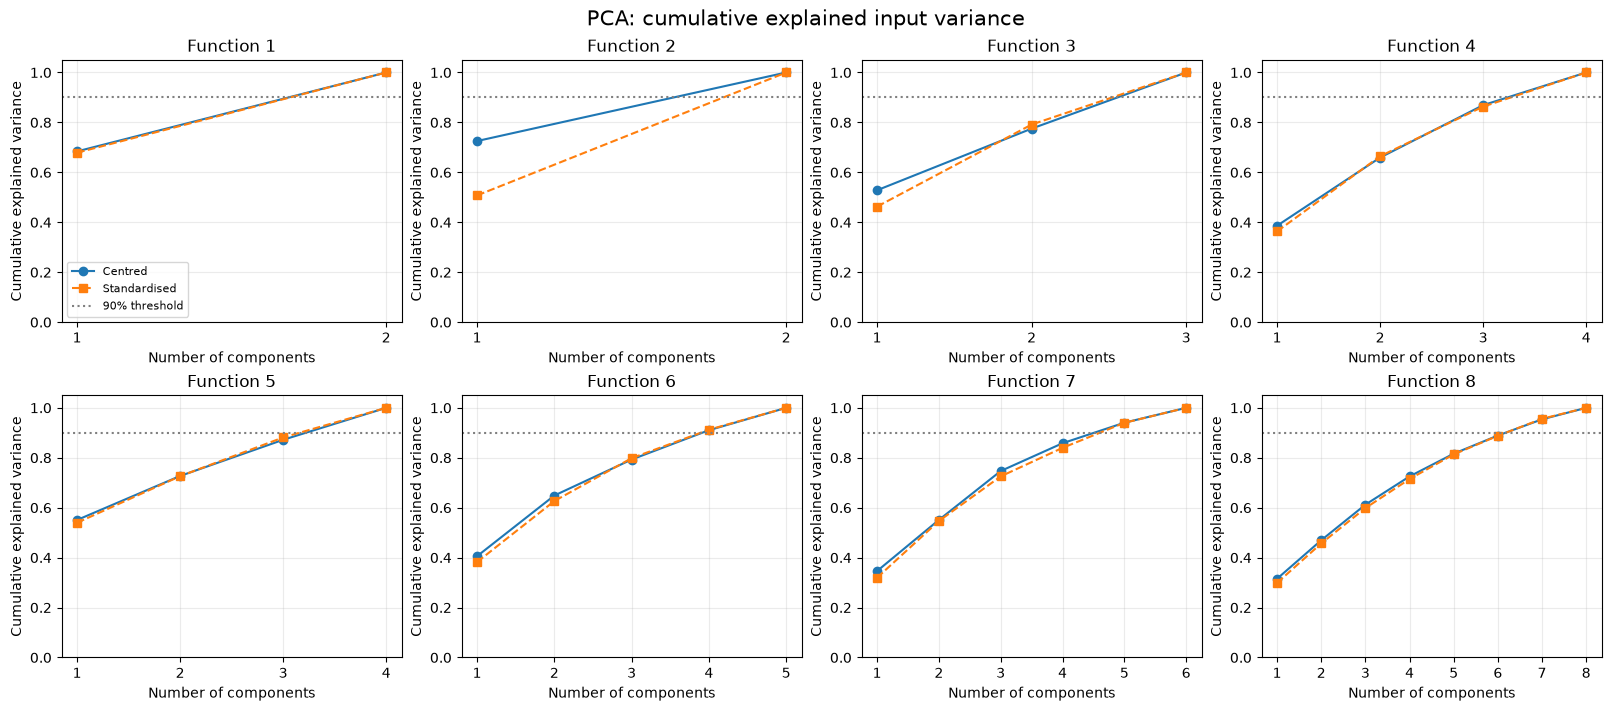

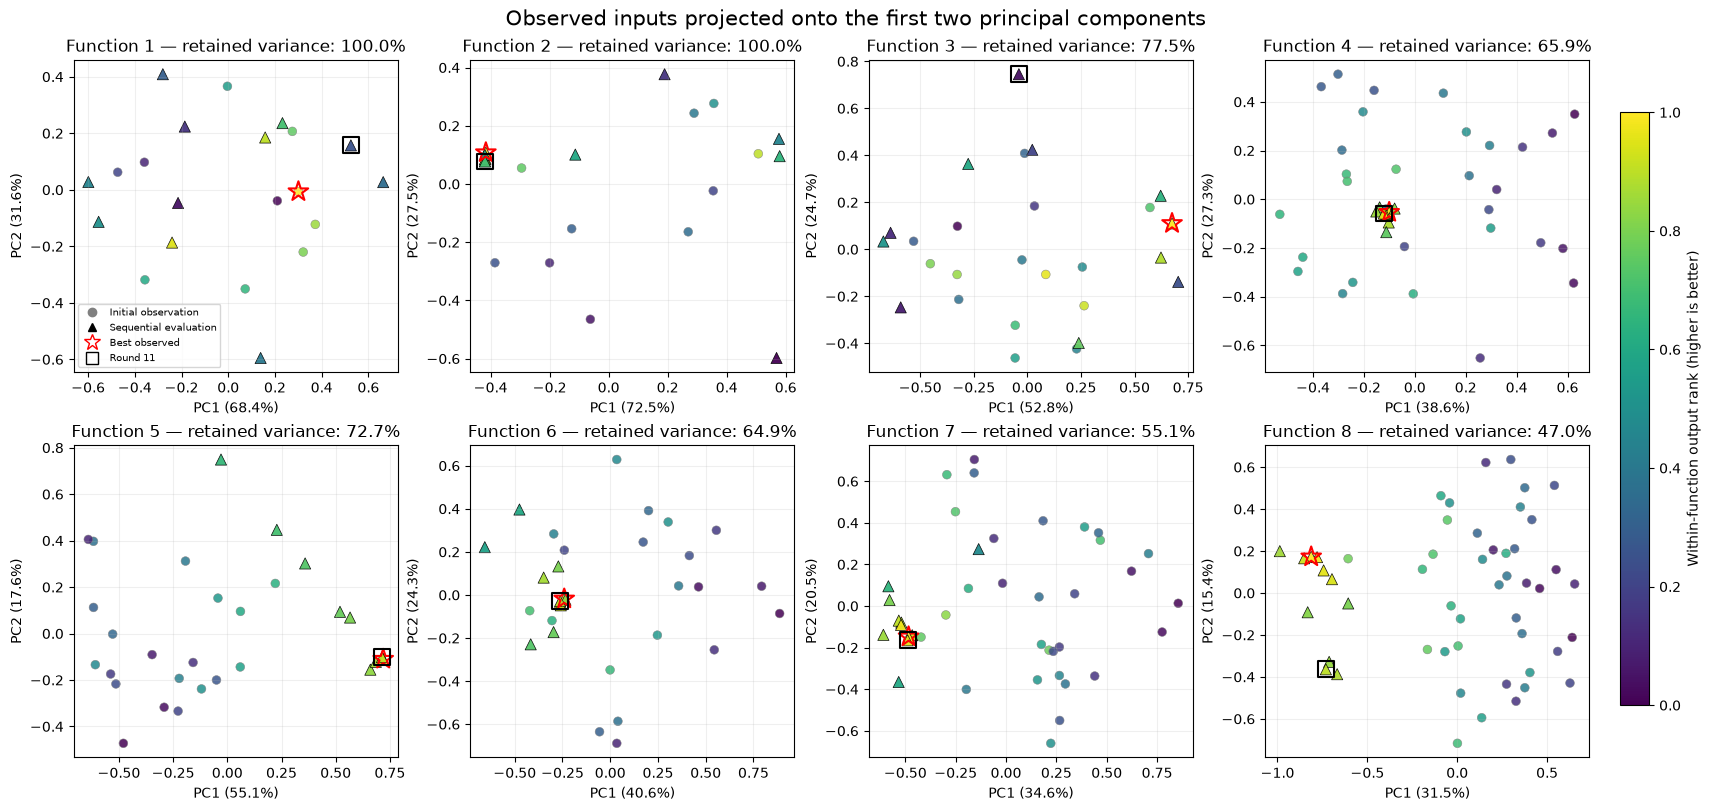

Colours show output ranks within each function, not comparable output magnitudes across functions.
For Function 1, rank differences can reflect extremely small numerical differences in outputs.
PCA projections describe sampled input structure; they do not establish objective sensitivity or causality.
All original coordinates will be retained when fitting the optimisation models.


In [7]:
# Visualise explained input variance and PCA projections.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

required_variables = [
    "pca_diagnostics",
    "updated_data",
    "completed_rounds",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the PCA analysis cell before this cell. "
        f"Missing variables: {', '.join(missing_variables)}"
    )

# Figure 1: cumulative explained variance.
fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 7),
    constrained_layout=True,
)

for function_id, ax in zip(range(1, 9), axes.flat):
    diagnostics = pca_diagnostics[function_id]

    centred_ratio = diagnostics[
        "centred_model"
    ].explained_variance_ratio_

    standardised_ratio = diagnostics[
        "standardised_model"
    ].explained_variance_ratio_

    components = np.arange(1, len(centred_ratio) + 1)

    ax.plot(
        components,
        np.cumsum(centred_ratio),
        marker="o",
        label="Centred",
    )

    ax.plot(
        components,
        np.cumsum(standardised_ratio),
        marker="s",
        linestyle="--",
        label="Standardised",
    )

    ax.axhline(
        0.90,
        color="grey",
        linestyle=":",
        label="90% threshold",
    )

    ax.set_title(f"Function {function_id}")
    ax.set_xlabel("Number of components")
    ax.set_ylabel("Cumulative explained variance")
    ax.set_xticks(components)
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.25)

axes[0, 0].legend(fontsize=8)

fig.suptitle(
    "PCA: cumulative explained input variance",
    fontsize=15,
)

plt.show()

# Figure 2: PCA scores coloured by within-function output rank.
fig, axes = plt.subplots(
    2, 4,
    figsize=(17, 8),
    constrained_layout=True,
)

colour_norm = Normalize(vmin=0.0, vmax=1.0)
colour_map = "viridis"

for function_id, ax in zip(range(1, 9), axes.flat):
    diagnostics = pca_diagnostics[function_id]

    scores = diagnostics["centred_scores"]
    explained = diagnostics["explained_variance_ratio"]
    rounds = diagnostics["observation_rounds"]

    y = np.asarray(
        updated_data[function_id]["y"],
        dtype=float,
    )

    assert len(scores) == len(y) == len(rounds)

    # Average ranks preserve exact ties.
    # Ranks are used only for colouring, not model fitting.
    ranks = pd.Series(y).rank(method="average").to_numpy()
    scaled_ranks = (ranks - 1.0) / (len(y) - 1.0)

    initial_mask = rounds == 0
    sequential_mask = rounds > 0

    ax.scatter(
        scores[initial_mask, 0],
        scores[initial_mask, 1],
        c=scaled_ranks[initial_mask],
        cmap=colour_map,
        norm=colour_norm,
        marker="o",
        s=40,
        edgecolors="grey",
        linewidths=0.4,
        alpha=0.85,
    )

    ax.scatter(
        scores[sequential_mask, 0],
        scores[sequential_mask, 1],
        c=scaled_ranks[sequential_mask],
        cmap=colour_map,
        norm=colour_norm,
        marker="^",
        s=65,
        edgecolors="black",
        linewidths=0.5,
        alpha=0.95,
    )

    best_index = int(np.argmax(y))
    latest_indices = np.flatnonzero(
        rounds == completed_rounds
    )

    assert len(latest_indices) == 1, (
        f"Function {function_id}: expected one latest observation."
    )

    latest_index = int(latest_indices[0])

    ax.scatter(
        scores[best_index, 0],
        scores[best_index, 1],
        marker="*",
        s=220,
        facecolors="none",
        edgecolors="red",
        linewidths=1.5,
        zorder=5,
    )

    ax.scatter(
        scores[latest_index, 0],
        scores[latest_index, 1],
        marker="s",
        s=130,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        zorder=6,
    )

    retained = explained[:2].sum()

    ax.set_title(
        f"Function {function_id} — retained variance: {retained:.1%}"
    )
    ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
    ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
    ax.grid(alpha=0.2)

legend_handles = [
    Line2D(
        [], [],
        marker="o",
        linestyle="none",
        color="grey",
        label="Initial observation",
    ),
    Line2D(
        [], [],
        marker="^",
        linestyle="none",
        color="black",
        label="Sequential evaluation",
    ),
    Line2D(
        [], [],
        marker="*",
        linestyle="none",
        markerfacecolor="none",
        markeredgecolor="red",
        markersize=12,
        label="Best observed",
    ),
    Line2D(
        [], [],
        marker="s",
        linestyle="none",
        markerfacecolor="none",
        markeredgecolor="black",
        markersize=9,
        label=f"Round {completed_rounds}",
    ),
]

axes[0, 0].legend(
    handles=legend_handles,
    fontsize=7,
    loc="best",
)

colour_scale = plt.cm.ScalarMappable(
    norm=colour_norm,
    cmap=colour_map,
)
colour_scale.set_array([])

fig.colorbar(
    colour_scale,
    ax=axes.ravel().tolist(),
    label="Within-function output rank (higher is better)",
    shrink=0.85,
    pad=0.02,
)

fig.suptitle(
    "Observed inputs projected onto the first two principal components",
    fontsize=15,
)

plt.show()

print(
    "Colours show output ranks within each function, "
    "not comparable output magnitudes across functions."
)
print(
    "For Function 1, rank differences can reflect extremely "
    "small numerical differences in outputs."
)
print(
    "PCA projections describe sampled input structure; "
    "they do not establish objective sensitivity or causality."
)
print(
    "All original coordinates will be retained "
    "when fitting the optimisation models."
)

### Interpretation of the visual patterns

Function 4 shows a tight concentration of sequential evaluations near
the projected best observation. Functions 5 and 7 also show several
high-ranked evaluations near their best observed points. These patterns
are consistent with repeated searches around promising regions, but
they partly reflect the adaptive sampling policy.

For Function 3, the latest evaluation lies away from the projected best
point and has a lower output rank. Function 8 also shows separation
between the latest evaluation and the best observation. However, its
two-component projection retains only 47% of input variance.

Function 1 does not show a clear, reliable high-performing region.
Its rank colours can exaggerate differences between outputs that are
numerically extremely close to zero.

The cumulative variance plots show that substantial dimensionality
reduction would discard considerable observed input variation.
All original coordinates are therefore retained for surrogate fitting.

## 7. Refit Gaussian Process models through round 11

A separate Gaussian Process is fitted to each function using its initial
observations and all eleven completed feedback rounds.

The Matérn smoothness settings and kernel parameter bounds are retained
from CP_22. Continuous kernel parameters are re-estimated by maximising
the log-marginal likelihood, with three optimiser restarts.

Models use the original input coordinates and normalise targets during
fitting. PCA scores are not used as model inputs.

Fitting warnings are recorded for transparency. Parameters reaching
their bounds may indicate sensitivity to modelling assumptions; they
do not by themselves establish that a variable is irrelevant or that
the model is invalid.

Predictive standard deviations remain model-dependent. The fitted
white-noise component can absorb measurement noise or model mismatch;
it does not establish that the underlying functions are stochastic.

In [8]:
# Refit Gaussian Processes using observations through round 11.

import warnings
from time import perf_counter

import numpy as np
import pandas as pd

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    Matern,
    WhiteKernel,
)
from IPython.display import display

required_variables = [
    "updated_data",
    "function_dimensions",
    "completed_rounds",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding data-loading cells before this cell. "
        f"Missing variables: {', '.join(missing_variables)}"
    )

# Retain the kernel configurations used in CP_22.
gp_configurations = {
    1: {
        "name": "Matern_1.5_original",
        "nu": 1.5,
        "upper_bound": 2.0,
    },
    2: {
        "name": "Matern_1.5_wider",
        "nu": 1.5,
        "upper_bound": 10.0,
    },
    3: {
        "name": "Matern_1.5_original",
        "nu": 1.5,
        "upper_bound": 2.0,
    },
    4: {
        "name": "Matern_1.5_wider",
        "nu": 1.5,
        "upper_bound": 10.0,
    },
    5: {
        "name": "Matern_1.5_original",
        "nu": 1.5,
        "upper_bound": 2.0,
    },
    6: {
        "name": "Matern_2.5_original",
        "nu": 2.5,
        "upper_bound": 2.0,
    },
    7: {
        "name": "Matern_2.5_original",
        "nu": 2.5,
        "upper_bound": 2.0,
    },
    8: {
        "name": "Matern_2.5_wider",
        "nu": 2.5,
        "upper_bound": 10.0,
    },
}

gp_models = {}
gp_fit_records = []
gp_warning_records = []

for function_id in range(1, 9):
    X = np.asarray(
        updated_data[function_id]["X"],
        dtype=float,
    )
    y = np.asarray(
        updated_data[function_id]["y"],
        dtype=float,
    ).reshape(-1)

    dimensions = function_dimensions[function_id]
    configuration = gp_configurations[function_id]

    assert X.shape == (len(y), dimensions)
    assert np.isfinite(X).all()
    assert np.isfinite(y).all()

    kernel = (
        ConstantKernel(
            constant_value=1.0,
            constant_value_bounds=(1e-3, 1e3),
        )
        * Matern(
            length_scale=np.full(dimensions, 0.2),
            length_scale_bounds=(
                0.02,
                configuration["upper_bound"],
            ),
            nu=configuration["nu"],
        )
        + WhiteKernel(
            noise_level=1e-6,
            noise_level_bounds=(1e-10, 0.1),
        )
    )

    model = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-10,
        normalize_y=True,
        n_restarts_optimizer=3,
        random_state=42,
    )

    start_time = perf_counter()

    with warnings.catch_warnings(record=True) as captured_warnings:
        warnings.simplefilter("always")
        model.fit(X, y)

    elapsed_seconds = perf_counter() - start_time

    gp_models[function_id] = model

    gp_fit_records.append({
        "Function": function_id,
        "Observations": len(y),
        "GP configuration": configuration["name"],
        "Fitted kernel": str(model.kernel_),
        "Log-marginal likelihood": (
            model.log_marginal_likelihood_value_
        ),
        "GP fit seconds": elapsed_seconds,
    })

    for warning in captured_warnings:
        gp_warning_records.append({
            "Function": function_id,
            "Category": warning.category.__name__,
            "Message": str(warning.message),
        })

gp_fit_summary_df = (
    pd.DataFrame(gp_fit_records)
    .set_index("Function")
    .sort_index()
)

gp_warnings_df = pd.DataFrame(
    gp_warning_records,
    columns=["Function", "Category", "Message"],
)

display(
    gp_fit_summary_df.style.format({
        "Log-marginal likelihood": "{:.6f}",
        "GP fit seconds": "{:.3f}",
    })
)

print(
    f"\nAll eight Gaussian Processes were fitted using "
    f"observations through round {completed_rounds}."
)
print(
    "Kernel configurations were retained from CP_22; "
    "continuous kernel parameters were re-estimated."
)
print("Models use all original input coordinates, not PCA scores.")
print("\nRecorded fitting warnings:", len(gp_warnings_df))

if not gp_warnings_df.empty:
    with pd.option_context("display.max_colwidth", None):
        display(gp_warnings_df)

,Observations,GP configuration,Fitted kernel,Log-marginal likelihood,GP fit seconds
Function,,,,,
1,21,Matern_1.5_original,"1.08**2 * Matern(length_scale=[2, 0.0403], nu=1.5) + WhiteKernel(noise_level=1.78e-08)",-28.014141,0.266
2,21,Matern_1.5_wider,"1.11**2 * Matern(length_scale=[0.114, 10], nu=1.5) + WhiteKernel(noise_level=0.0724)",-17.759485,0.139
3,26,Matern_1.5_original,"1.17**2 * Matern(length_scale=[2, 1.45, 0.0744], nu=1.5) + WhiteKernel(noise_level=1e-10)",-30.698255,0.187
4,41,Matern_1.5_wider,"4.63**2 * Matern(length_scale=[3.83, 3.52, 3.63, 3.74], nu=1.5) + WhiteKernel(noise_level=0.000257)",7.893746,0.314
5,31,Matern_1.5_original,"1.33**2 * Matern(length_scale=[1.86, 2, 1.27, 2], nu=1.5) + WhiteKernel(noise_level=0.00558)",-2.754732,0.236
6,31,Matern_2.5_original,"1.66**2 * Matern(length_scale=[1, 1.3, 1.39, 1.21, 2], nu=2.5) + WhiteKernel(noise_level=0.0214)",-19.022908,0.198
7,41,Matern_2.5_original,"0.617**2 * Matern(length_scale=[0.787, 2, 2, 0.187, 0.22, 0.216], nu=2.5) + WhiteKernel(noise_level=1e-10)",-22.840287,0.277
8,51,Matern_2.5_wider,"3.09**2 * Matern(length_scale=[3.32, 5.28, 2.75, 4.51, 10, 5.09, 3.46, 10], nu=2.5) + WhiteKernel(noise_level=1e-10)",21.009561,0.362



All eight Gaussian Processes were fitted using observations through round 11.
Kernel configurations were retained from CP_22; continuous kernel parameters were re-estimated.
Models use all original input coordinates, not PCA scores.

Recorded fitting warnings: 13


,Function,Category,Message
0,1,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
1,2,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
2,3,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
3,3,ConvergenceWarning,The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
4,5,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
5,5,ConvergenceWarning,The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
6,6,ConvergenceWarning,The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
7,7,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
8,7,ConvergenceWarning,The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
9,7,ConvergenceWarning,The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.


### Interpretation of the fitted models

Thirteen fitting warnings were recorded, all concerning parameters
close to their specified bounds. These warnings are retained as evidence
of possible sensitivity to the modelling assumptions. Bounds are not
changed automatically in response to a warning.

Function 3 illustrates the distinction between PCA and surrogate
modelling. Its fitted GP length scale for x3 is much shorter than those
for x1 and x2, whereas x3 contributes relatively little to the first
input principal component. Input variance and modelled output sensitivity
therefore provide different information.

Length scales remain model-dependent and can change as observations
are added. Neither PCA weights nor fitted kernel parameters establish
causal importance.

## 8. Refit auxiliary models

The auxiliary models from CP_22 are refitted using observations through
round 11: a neural network with one hidden layer of eight units for
Function 5, and linear regression for Function 7.

Inputs and targets are standardised within the modelling pipelines.
Predictions are returned in the original output units.

These models provide diagnostic comparisons with the GP predictions.
They do not supply the uncertainty estimates used in UCB and do not
replace the GP acquisition rule.

In round 11, the GP had lower absolute error than the auxiliary model
for both functions. The Function 7 linear model substantially
underpredicted the observed output, so its predictions should be
interpreted cautiously.

In [9]:
# Refit auxiliary models using observations through round 11.

import warnings
from time import perf_counter

import numpy as np
import pandas as pd

from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

required_variables = [
    "updated_data",
    "completed_rounds",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding data-loading cells before this cell. "
        f"Missing variables: {', '.join(missing_variables)}"
    )

auxiliary_configurations = {
    5: {
        "name": "NN (8,)",
        "regressor": MLPRegressor(
            hidden_layer_sizes=(8,),
            activation="tanh",
            solver="lbfgs",
            alpha=0.1,
            max_iter=2000,
            random_state=42,
        ),
    },
    7: {
        "name": "Linear regression",
        "regressor": LinearRegression(),
    },
}

auxiliary_models = {}
auxiliary_fit_records = []
auxiliary_warning_records = []

for function_id, configuration in auxiliary_configurations.items():
    X = np.asarray(
        updated_data[function_id]["X"],
        dtype=float,
    )
    y = np.asarray(
        updated_data[function_id]["y"],
        dtype=float,
    ).reshape(-1)

    assert len(X) == len(y)
    assert np.isfinite(X).all()
    assert np.isfinite(y).all()

    input_pipeline = Pipeline([
        ("input_scaler", StandardScaler()),
        ("regressor", configuration["regressor"]),
    ])

    model = TransformedTargetRegressor(
        regressor=input_pipeline,
        transformer=StandardScaler(),
    )

    start_time = perf_counter()

    with warnings.catch_warnings(record=True) as captured_warnings:
        warnings.simplefilter("always")
        model.fit(X, y)

    elapsed_seconds = perf_counter() - start_time

    auxiliary_models[function_id] = model

    auxiliary_fit_records.append({
        "Function": function_id,
        "Observations": len(y),
        "Auxiliary model": configuration["name"],
        "Fit seconds": elapsed_seconds,
    })

    for warning in captured_warnings:
        auxiliary_warning_records.append({
            "Function": function_id,
            "Category": warning.category.__name__,
            "Message": str(warning.message),
        })

auxiliary_fit_summary_df = (
    pd.DataFrame(auxiliary_fit_records)
    .set_index("Function")
    .sort_index()
)

auxiliary_warnings_df = pd.DataFrame(
    auxiliary_warning_records,
    columns=["Function", "Category", "Message"],
)

display(
    auxiliary_fit_summary_df.style.format({
        "Fit seconds": "{:.3f}",
    })
)

print(
    "\nAuxiliary models fitted for Functions 5 and 7 "
    f"using observations through round {completed_rounds}."
)
print("Predictions will be returned in the original output units.")

if auxiliary_warnings_df.empty:
    print("No auxiliary fitting warnings were recorded.")
else:
    print(
        "Recorded auxiliary fitting warnings:",
        len(auxiliary_warnings_df),
    )
    with pd.option_context("display.max_colwidth", None):
        display(auxiliary_warnings_df)

,Observations,Auxiliary model,Fit seconds
Function,,,
5,31,"NN (8,)",0.092
7,41,Linear regression,0.010



Auxiliary models fitted for Functions 5 and 7 using observations through round 11.
Predictions will be returned in the original output units.
No auxiliary fitting warnings were recorded.


## 9. Generate and compare round-12 candidates

Candidate searches use all original input coordinates. Each function
receives 100,000 global random candidates and 10,000 candidates in each
of two local boxes around its best observed point, with coordinate
half-widths of 0.10 and 0.03.

The random seed is recorded and varies by function and submission round,
providing reproducible, refreshed candidate pools.

Coordinates are rounded to six decimals before prediction and distance
checks. Duplicate candidates are removed, and candidates within the
configured duplicate tolerance of an observed input are excluded.

Candidates are ranked by UCB = predicted mean + 2 × predictive standard
deviation. The predictive standard deviation includes the fitted
WhiteKernel contribution.

For Function 5, standard proposals are compared with alternatives at
least 0.01 Euclidean distance from every observed input. Both use the
same candidate pools and predictions. This constraint reduces very
close repetition but does not guarantee better outcomes.

Distances are calculated in the original input space. RMS distance
equals Euclidean distance divided by the square root of dimensionality.
PCA remains an interpretative tool and does not restrict the search.

This cell prepares proposals only; final queries are selected afterwards.

In [11]:
# Generate and compare candidates for round 12.

from time import perf_counter

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from IPython.display import display

required_variables = [
    "updated_data",
    "gp_models",
    "auxiliary_models",
    "submission_round",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding model-fitting cells before this cell. "
        f"Missing variables: {', '.join(missing_variables)}"
    )

candidate_search_settings = {
    "global_candidates": 100_000,
    "local_candidates": 10_000,
    "local_half_widths": (0.10, 0.03),
    "ucb_weight": 2.0,
    "duplicate_tolerance": 1e-6,
    "f5_minimum_distance": 0.01,
    "prediction_batch_size": 5_000,
    "base_seed": 42,
    "submission_round": submission_round,
}

candidate_records = []
candidate_time_records = []
candidate_seeds = {}


def format_query(coordinates):
    """Format a query for manual portal submission."""
    return "-".join(f"{value:.6f}" for value in coordinates)


def predict_in_batches(model, candidates, batch_size):
    """Return GP predictions without evaluating all candidates at once."""
    means = []
    standard_deviations = []

    for start in range(0, len(candidates), batch_size):
        batch = candidates[start:start + batch_size]
        batch_mean, batch_std = model.predict(
            batch,
            return_std=True,
        )
        means.append(batch_mean)
        standard_deviations.append(batch_std)

    return (
        np.concatenate(means),
        np.concatenate(standard_deviations),
    )


for function_id in range(1, 9):
    start_time = perf_counter()

    X = np.asarray(updated_data[function_id]["X"], dtype=float)
    y = np.asarray(updated_data[function_id]["y"], dtype=float)

    dimensions = X.shape[1]
    best_index = int(np.argmax(y))
    best_coordinates = X[best_index]
    current_best = float(y[best_index])

    observation_tree = cKDTree(X)

    seed = (
        candidate_search_settings["base_seed"]
        + 1_000 * submission_round
        + function_id
    )
    candidate_seeds[function_id] = seed
    rng = np.random.default_rng(seed)

    search_pools = {
        "Global": rng.uniform(
            0.0,
            1.0,
            size=(
                candidate_search_settings["global_candidates"],
                dimensions,
            ),
        )
    }

    for half_width in candidate_search_settings["local_half_widths"]:
        lower_bounds = np.maximum(
            0.0,
            best_coordinates - half_width,
        )
        upper_bounds = np.minimum(
            1.0,
            best_coordinates + half_width,
        )

        search_pools[f"Local {half_width:.2f}"] = rng.uniform(
            lower_bounds,
            upper_bounds,
            size=(
                candidate_search_settings["local_candidates"],
                dimensions,
            ),
        )

    for search_name, raw_candidates in search_pools.items():
        # Evaluate the exact six-decimal coordinates that could be submitted.
        candidates = np.unique(
            np.round(raw_candidates, decimals=6),
            axis=0,
        )

        # Submission strings must retain the 0.xxxxxx format.
        bounds_mask = (
            (candidates >= 0.0) & (candidates < 1.0)
        ).all(axis=1)
        candidates = candidates[bounds_mask]

        if len(candidates) == 0:
            raise RuntimeError(
                f"Function {function_id}, {search_name}: "
                "no candidates remain within submission bounds."
            )

        nearest_distances, _ = observation_tree.query(
            candidates,
            k=1,
        )

        novel_mask = (
            nearest_distances
            > candidate_search_settings["duplicate_tolerance"]
        )

        candidates = candidates[novel_mask]
        nearest_distances = nearest_distances[novel_mask]

        if len(candidates) == 0:
            raise RuntimeError(
                f"Function {function_id}, {search_name}: "
                "no candidates remain after duplicate filtering."
            )

        means, standard_deviations = predict_in_batches(
            gp_models[function_id],
            candidates,
            candidate_search_settings["prediction_batch_size"],
        )

        assert np.isfinite(means).all()
        assert np.isfinite(standard_deviations).all()
        assert (standard_deviations >= 0.0).all()

        ucb_scores = (
            means
            + candidate_search_settings["ucb_weight"]
            * standard_deviations
        )

        proposal_masks = {
            "Standard": np.ones(len(candidates), dtype=bool)
        }

        if function_id == 5:
            proposal_masks["Distance >= 0.01"] = (
                nearest_distances
                >= candidate_search_settings["f5_minimum_distance"]
            )

        for proposal_name, eligible_mask in proposal_masks.items():
            eligible_indices = np.flatnonzero(eligible_mask)

            if len(eligible_indices) == 0:
                raise RuntimeError(
                    f"Function {function_id}, {search_name}, "
                    f"{proposal_name}: no eligible candidates."
                )

            winner_index = eligible_indices[
                np.argmax(ucb_scores[eligible_indices])
            ]
            query = candidates[winner_index]

            auxiliary_prediction = np.nan
            if function_id in auxiliary_models:
                auxiliary_prediction = float(
                    auxiliary_models[function_id]
                    .predict(query.reshape(1, -1))[0]
                )

            distances_to_observations = np.linalg.norm(
                X - query,
                axis=1,
            )
            rms_distances = (
                distances_to_observations / np.sqrt(dimensions)
            )

            candidate_records.append({
                "Function": function_id,
                "Search": search_name,
                "Proposal": proposal_name,
                "Query": format_query(query),
                "Current best": current_best,
                "GP mean": float(means[winner_index]),
                "GP std": float(
                    standard_deviations[winner_index]
                ),
                "UCB": float(ucb_scores[winner_index]),
                "Nearest observation distance": float(
                    nearest_distances[winner_index]
                ),
                "Nearest observation distance (RMS)": float(
                    nearest_distances[winner_index]
                    / np.sqrt(dimensions)
                ),
                "Distance to best (RMS)": float(
                    np.linalg.norm(query - best_coordinates)
                    / np.sqrt(dimensions)
                ),
                "Neighbours within RMS 0.10": int(
                    np.count_nonzero(rms_distances <= 0.10)
                ),
                "Auxiliary prediction": auxiliary_prediction,
                "Eligible candidates": len(eligible_indices),
                "Seed": seed,
            })

    candidate_time_records.append({
        "Function": function_id,
        "Candidate search seconds": (
            perf_counter() - start_time
        ),
    })

candidate_comparison_df = pd.DataFrame(candidate_records)

candidate_search_times_df = (
    pd.DataFrame(candidate_time_records)
    .set_index("Function")
    .sort_index()
)

main_columns = [
    "Function",
    "Search",
    "Proposal",
    "Query",
    "Current best",
    "GP mean",
    "GP std",
    "UCB",
    "Nearest observation distance",
    "Auxiliary prediction",
]

main_formatters = {
    column: "{:.6e}"
    for column in [
        "Current best",
        "GP mean",
        "GP std",
        "UCB",
        "Auxiliary prediction",
    ]
}
main_formatters["Nearest observation distance"] = "{:.6f}"

display(
    candidate_comparison_df[main_columns].style.format(
        main_formatters,
        na_rep="—",
    )
)

print("\nOriginal-space distance diagnostics")

context_columns = [
    "Function",
    "Search",
    "Proposal",
    "Nearest observation distance (RMS)",
    "Distance to best (RMS)",
    "Neighbours within RMS 0.10",
    "Eligible candidates",
    "Seed",
]

display(
    candidate_comparison_df[context_columns].style.format({
        "Nearest observation distance (RMS)": "{:.6f}",
        "Distance to best (RMS)": "{:.6f}",
    })
)

print("\nCandidate search time")

display(
    candidate_search_times_df.style.format({
        "Candidate search seconds": "{:.3f}",
    })
)

assert len(candidate_comparison_df) == 27, (
    "Expected 24 standard proposals and three F5 alternatives."
)

print(
    "\nProposals are ready for comparison; "
    "final queries have not yet been selected."
)
print(
    "F5 alternatives use the same candidate pools and predictions "
    "as the standard proposals."
)
print(
    "Candidate pools use reproducible seeds that vary "
    "by function and submission round."
)

,Function,Search,Proposal,Query,Current best,GP mean,GP std,UCB,Nearest observation distance,Auxiliary prediction
0,1,Global,Standard,0.000794-0.306216,7.710875e-16,-5.191403e-05,6.765328e-04,1.301151e-03,0.127039,—
1,1,Local 0.10,Standard,0.636456-0.832764,7.710875e-16,-1.097828e-05,4.224116e-04,8.338450e-04,0.054827,—
2,1,Local 0.03,Standard,0.759833-0.749739,7.710875e-16,1.716733e-04,2.831440e-04,7.379612e-04,0.033319,—
3,2,Global,Standard,0.695444-0.008679,6.582395e-01,5.687876e-01,7.309364e-02,7.149748e-01,0.007893,—
4,2,Local 0.10,Standard,0.694974-0.000322,6.582395e-01,5.686974e-01,7.318871e-02,7.150748e-01,0.003166,—
5,2,Local 0.03,Standard,0.695216-0.000340,6.582395e-01,5.687673e-01,7.315649e-02,7.150803e-01,0.002993,—
6,3,Global,Standard,0.009599-0.996723-0.489470,-3.096391e-02,-3.609319e-02,4.468820e-02,5.328321e-02,0.316487,—
7,3,Local 0.10,Standard,0.975904-0.999991-0.463187,-3.096391e-02,-4.357110e-02,4.103986e-02,3.850861e-02,0.059886,—
8,3,Local 0.03,Standard,0.972359-0.993923-0.475541,-3.096391e-02,-3.876779e-02,3.569829e-02,3.262879e-02,0.049801,—
9,4,Global,Standard,0.372216-0.385189-0.397784-0.431730,6.152729e-01,1.415438e-01,2.252523e-01,5.920484e-01,0.044866,—



Original-space distance diagnostics


,Function,Search,Proposal,Nearest observation distance (RMS),Distance to best (RMS),Neighbours within RMS 0.10,Eligible candidates,Seed
0,1,Global,Standard,0.089830,0.598072,1,99999,12043
1,1,Local 0.10,Standard,0.038768,0.097201,3,10000,12043
2,1,Local 0.03,Standard,0.023560,0.023560,3,10000,12043
3,2,Global,Standard,0.005581,0.018192,7,100000,12044
4,2,Local 0.10,Standard,0.002239,0.018342,7,10000,12044
5,2,Local 0.03,Standard,0.002116,0.018171,7,10000,12044
6,3,Global,Standard,0.182724,0.571789,0,100000,12045
7,3,Local 0.10,Standard,0.034575,0.034575,2,10000,12045
8,3,Local 0.03,Standard,0.028753,0.028753,3,10000,12045
9,4,Global,Standard,0.022433,0.034804,11,100000,12046



Candidate search time


,Candidate search seconds
Function,
1,0.412
2,0.402
3,0.504
4,0.572
5,0.555
6,0.700
7,0.740
8,0.866



Proposals are ready for comparison; final queries have not yet been selected.
F5 alternatives use the same candidate pools and predictions as the standard proposals.
Candidate pools use reproducible seeds that vary by function and submission round.


,Function,Search,Proposal,Query,Current best,GP mean,GP std,UCB,Nearest observation distance,Auxiliary prediction
0,1,Global,Standard,0.000794-0.306216,7.710875e-16,-5.191403e-05,6.765328e-04,1.301151e-03,0.127039,—
1,1,Local 0.10,Standard,0.636456-0.832764,7.710875e-16,-1.097828e-05,4.224116e-04,8.338450e-04,0.054827,—
2,1,Local 0.03,Standard,0.759833-0.749739,7.710875e-16,1.716733e-04,2.831440e-04,7.379612e-04,0.033319,—
3,2,Global,Standard,0.695444-0.008679,6.582395e-01,5.687876e-01,7.309364e-02,7.149748e-01,0.007893,—
4,2,Local 0.10,Standard,0.694974-0.000322,6.582395e-01,5.686974e-01,7.318871e-02,7.150748e-01,0.003166,—
5,2,Local 0.03,Standard,0.695216-0.000340,6.582395e-01,5.687673e-01,7.315649e-02,7.150803e-01,0.002993,—
6,3,Global,Standard,0.009599-0.996723-0.489470,-3.096391e-02,-3.609319e-02,4.468820e-02,5.328321e-02,0.316487,—
7,3,Local 0.10,Standard,0.975904-0.999991-0.463187,-3.096391e-02,-4.357110e-02,4.103986e-02,3.850861e-02,0.059886,—
8,3,Local 0.03,Standard,0.972359-0.993923-0.475541,-3.096391e-02,-3.876779e-02,3.569829e-02,3.262879e-02,0.049801,—
9,4,Global,Standard,0.372216-0.385189-0.397784-0.431730,6.152729e-01,1.415438e-01,2.252523e-01,5.920484e-01,0.044866,—



Original-space distance diagnostics


,Function,Search,Proposal,Nearest observation distance (RMS),Distance to best (RMS),Neighbours within RMS 0.10,Eligible candidates,Seed
0,1,Global,Standard,0.089830,0.598072,1,99999,12043
1,1,Local 0.10,Standard,0.038768,0.097201,3,10000,12043
2,1,Local 0.03,Standard,0.023560,0.023560,3,10000,12043
3,2,Global,Standard,0.005581,0.018192,7,100000,12044
4,2,Local 0.10,Standard,0.002239,0.018342,7,10000,12044
5,2,Local 0.03,Standard,0.002116,0.018171,7,10000,12044
6,3,Global,Standard,0.182724,0.571789,0,100000,12045
7,3,Local 0.10,Standard,0.034575,0.034575,2,10000,12045
8,3,Local 0.03,Standard,0.028753,0.028753,3,10000,12045
9,4,Global,Standard,0.022433,0.034804,11,100000,12046



Candidate search time


,Candidate search seconds
Function,
1,0.611
2,1.047
3,0.911
4,1.680
5,0.839
6,0.549
7,0.654
8,0.946



Proposals are ready for comparison; final queries have not yet been selected.
F5 alternatives use the same candidate pools and predictions as the standard proposals.
Candidate pools use reproducible seeds that vary by function and submission round.


## 10. Final query selection and validation

I select the highest-UCB proposal for each function using the full
numerical scores stored in memory. For Function 5, I retain the minimum
Euclidean distance of 0.01 from existing observations and select the
highest-UCB proposal satisfying that constraint.

The resulting choices combine global proposals for Functions 1, 3 and 7
with local proposals for Functions 2, 4, 5, 6 and 8. These labels describe
the candidate generation method; they do not establish that a proposal
is a global or local optimum.

Function 5's distance constraint is a deliberate attempt to reduce
near-redundant evaluations. Its failure to improve in round 11 does not
establish whether the unconstrained alternative would have performed
better, because that alternative was not evaluated.

Functions 2 and 4 still select points close to existing observations.
Their proposals satisfy the general duplicate tolerance, but this does
not guarantee substantial new information. Function 7 selects a more
distant proposal with a lower predicted mean and higher uncertainty
than its local alternatives.

PCA informs the interpretation of the sampled input structure. It does
not determine the UCB scores or remove any coordinates from the models.

Before submission, each query is checked for dimensionality, finite
values, permitted bounds, six-decimal formatting and its applicable
distance constraint. Predictions and UCB scores remain separate from
observed outputs.

In [12]:
# CP_23 — Round 12
# Select and validate one query per function.

import re

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from IPython.display import display

required_variables = [
    "candidate_comparison_df",
    "candidate_search_settings",
    "updated_data",
    "submission_round",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding notebook cells first. Missing variables: "
        + ", ".join(missing_variables)
    )

required_columns = [
    "Function",
    "Search",
    "Proposal",
    "Query",
    "GP mean",
    "GP std",
    "UCB",
    "Nearest observation distance",
    "Auxiliary prediction",
]

missing_columns = [
    column for column in required_columns
    if column not in candidate_comparison_df.columns
]

if missing_columns:
    raise RuntimeError(
        "The candidate table is missing columns: "
        + ", ".join(missing_columns)
    )

duplicate_tolerance = float(
    candidate_search_settings["duplicate_tolerance"]
)
f5_minimum_distance = float(
    candidate_search_settings["f5_minimum_distance"]
)
ucb_weight = float(candidate_search_settings["ucb_weight"])

selected_rows = []
selected_queries = {}
validation_rows = []

for function_id in range(1, 9):
    function_candidates = candidate_comparison_df.loc[
        candidate_comparison_df["Function"] == function_id
    ].copy()

    # Retain the existing F5 distance-constrained selection policy.
    if function_id == 5:
        eligible = function_candidates.loc[
            (function_candidates["Proposal"] == "Distance >= 0.01")
            & (
                function_candidates["Nearest observation distance"]
                >= f5_minimum_distance
            )
        ].copy()
    else:
        eligible = function_candidates.loc[
            function_candidates["Proposal"] == "Standard"
        ].copy()

    if eligible.empty:
        raise RuntimeError(
            f"No eligible proposal is available for Function {function_id}."
        )

    scores = eligible["UCB"].to_numpy(dtype=float)
    if not np.all(np.isfinite(scores)):
        raise ValueError(
            f"Non-finite UCB scores for Function {function_id}."
        )

    # Select using full stored precision, not displayed rounded scores.
    winner = eligible.loc[eligible["UCB"].idxmax()].copy()

    query_string = str(winner["Query"])
    X = np.asarray(updated_data[function_id]["X"], dtype=float)
    dimensions = X.shape[1]

    pattern = r"0\.\d{6}(?:-0\.\d{6}){" + str(dimensions - 1) + r"}"

    if re.fullmatch(pattern, query_string) is None:
        raise ValueError(
            f"Invalid submission format for Function {function_id}: "
            f"{query_string}"
        )

    query = np.array(
        [float(value) for value in query_string.split("-")],
        dtype=float,
    )

    if query.shape != (dimensions,):
        raise ValueError(
            f"Incorrect query dimensionality for Function {function_id}."
        )

    if not np.all(np.isfinite(query)):
        raise ValueError(
            f"Non-finite coordinates for Function {function_id}."
        )

    if np.any(query < 0.0) or np.any(query >= 1.0):
        raise ValueError(
            f"Coordinates outside the submission bounds "
            f"for Function {function_id}."
        )

    # Recheck distances using the exact six-decimal submission query.
    nearest_distance = float(cKDTree(X).query(query, k=1)[0])

    if nearest_distance <= duplicate_tolerance:
        raise ValueError(
            f"Function {function_id} violates the duplicate tolerance."
        )

    if (
        function_id == 5
        and nearest_distance < f5_minimum_distance
    ):
        raise ValueError(
            "Function 5 violates the minimum Euclidean distance of 0.01."
        )

    mean = float(winner["GP mean"])
    std = float(winner["GP std"])
    ucb = float(winner["UCB"])

    if not np.all(np.isfinite([mean, std, ucb])) or std < 0:
        raise ValueError(
            f"Invalid predictive values for Function {function_id}."
        )

    if not np.isclose(
        ucb,
        mean + ucb_weight * std,
        rtol=1e-9,
        atol=1e-12,
    ):
        raise ValueError(
            f"Inconsistent UCB calculation for Function {function_id}."
        )

    winner["Nearest observation distance"] = nearest_distance
    selected_rows.append(winner)
    selected_queries[function_id] = query.copy()

    validation_rows.append({
        "Function": function_id,
        "Dimensions": dimensions,
        "Format valid": True,
        "Bounds valid": True,
        "Distance constraint satisfied": True,
        "Nearest observation distance": nearest_distance,
    })

selected_candidates_df = (
    pd.DataFrame(selected_rows)
    .set_index("Function")
    .sort_index()
    .rename(columns={
        "Search": "Selected search",
        "GP mean": "Predicted mean",
        "GP std": "Predicted std",
    })
)

submission_queries_df = (
    selected_candidates_df[["Query"]]
    .rename(columns={"Query": "Query for submission"})
    .copy()
)

query_validation_df = (
    pd.DataFrame(validation_rows)
    .set_index("Function")
    .sort_index()
)

# Retain predictions for comparison with future portal feedback.
round12_predictions_df = selected_candidates_df[[
    "Query",
    "Predicted mean",
    "Predicted std",
    "UCB",
    "Auxiliary prediction",
]].copy()

f5_standard_ucb = float(
    candidate_comparison_df.loc[
        (candidate_comparison_df["Function"] == 5)
        & (candidate_comparison_df["Proposal"] == "Standard"),
        "UCB",
    ].max()
)

f5_selected_ucb = float(selected_candidates_df.loc[5, "UCB"])
f5_ucb_reduction = f5_standard_ucb - f5_selected_ucb
f5_ucb_reduction_percent = (
    100.0 * f5_ucb_reduction / abs(f5_standard_ucb)
    if f5_standard_ucb != 0.0
    else np.nan
)

display_columns = [
    "Selected search",
    "Proposal",
    "Query",
    "Predicted mean",
    "Predicted std",
    "UCB",
    "Nearest observation distance",
    "Auxiliary prediction",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_columns", None,
):
    display(selected_candidates_df[display_columns])
    display(submission_queries_df)

print(f"\nRound {submission_round} — queries for manual submission\n")

for function_id, row in submission_queries_df.iterrows():
    print(f"Function {function_id}: {row['Query for submission']}")

print(
    "\nF5 UCB reduction relative to its standard winner: "
    f"{f5_ucb_reduction:.6f} "
    f"({f5_ucb_reduction_percent:.3f}%)."
)

print("\nAll eight queries passed validation.")
print(
    "Validation confirms format, bounds and the configured distance "
    "constraints; it does not guarantee improvement."
)
print(
    "Queries are prepared; this code does not submit them to the portal."
)

,Selected search,Proposal,Query,Predicted mean,Predicted std,UCB,Nearest observation distance,Auxiliary prediction
Function,,,,,,,,
1,Global,Standard,0.000794-0.306216,-0.000052,0.000677,0.001301,0.127039,NaN
2,Local 0.03,Standard,0.695216-0.000340,0.568767,0.073156,0.715080,0.002993,NaN
3,Global,Standard,0.009599-0.996723-0.489470,-0.036093,0.044688,0.053283,0.316487,NaN
4,Local 0.03,Standard,0.401292-0.414900-0.382216-0.419184,0.438296,0.175084,0.788463,0.006379,NaN
5,Local 0.03,Distance >= 0.01,0.986568-0.998687-0.999548-0.999338,8206.489417,255.473602,8717.436621,0.010475,8146.865978
6,Local 0.10,Standard,0.474194-0.394624-0.550990-0.711773-0.003309,-0.356637,0.095132,-0.166374,0.033377,NaN
7,Global,Standard,0.023970-0.738916-0.861002-0.151043-0.315073-0.719810,2.216998,0.169534,2.556066,0.293405,1.286454
8,Local 0.10,Standard,0.147547-0.091396-0.058935-0.207967-0.996495-0.564027-0.249450-0.839157,9.961708,0.017542,9.996791,0.172655,NaN


,Query for submission
Function,
1,0.000794-0.306216
2,0.695216-0.000340
3,0.009599-0.996723-0.489470
4,0.401292-0.414900-0.382216-0.419184
5,0.986568-0.998687-0.999548-0.999338
6,0.474194-0.394624-0.550990-0.711773-0.003309
7,0.023970-0.738916-0.861002-0.151043-0.315073-0.719810
8,0.147547-0.091396-0.058935-0.207967-0.996495-0.564027-0.249450-0.839157



Round 12 — queries for manual submission

Function 1: 0.000794-0.306216
Function 2: 0.695216-0.000340
Function 3: 0.009599-0.996723-0.489470
Function 4: 0.401292-0.414900-0.382216-0.419184
Function 5: 0.986568-0.998687-0.999548-0.999338
Function 6: 0.474194-0.394624-0.550990-0.711773-0.003309
Function 7: 0.023970-0.738916-0.861002-0.151043-0.315073-0.719810
Function 8: 0.147547-0.091396-0.058935-0.207967-0.996495-0.564027-0.249450-0.839157

F5 UCB reduction relative to its standard winner: 62.761754 (0.715%).

All eight queries passed validation.
Validation confirms format, bounds and the configured distance constraints; it does not guarantee improvement.
Queries are prepared; this code does not submit them to the portal.


## 11. Interpretation and preparation for the final round

Round 12 combines global proposals for Functions 1, 3 and 7 with local
proposals for Functions 2, 4, 5, 6 and 8. Selection follows the highest
eligible UCB, calculated as the GP mean plus twice its predictive
standard deviation.

### Interpretation of the selected queries

- **Function 1:** The global proposal prioritises uncertainty despite a
  negative predicted mean. Previous near-zero outputs provide limited
  evidence for locating a better region.

- **Function 2:** Local refinement continues near the lower boundary of
  the second coordinate. The selected point is only 0.002993 from an
  existing observation, so its additional information may be limited.
  The UCB difference between the two local proposals is very small.

- **Function 3:** The global proposal tests a different combination,
  with the first coordinate near zero and the third near 0.49.
  Its higher uncertainty contributes to its selection. The unsuccessful
  global query in round 11 cautions against assuming exploration will
  immediately improve the best result.

- **Function 4:** The selected point refines the repeatedly sampled
  interior region. Recent outputs remain below the best observation,
  and proximity alone does not guarantee improvement.

- **Function 5:** The selected proposal remains near the upper
  boundaries while satisfying a minimum Euclidean distance of 0.01.
  Its nearest-observation distance is 0.010475. This constraint reduces
  UCB by 62.761754, or 0.715%, relative to the unconstrained winner.
  The trade-off favours greater separation without claiming that it
  will produce a better outcome.

- **Function 6:** The Local 0.10 proposal has the highest UCB, although
  its predicted mean remains below the current best. Its negative
  UCB is still valid because the objective is maximisation.

- **Function 7:** The global proposal has a lower predicted mean but
  greater uncertainty than the local alternatives. The substantial
  disagreement with linear regression remains a diagnostic concern;
  the auxiliary prediction does not determine selection.

- **Function 8:** The Local 0.10 proposal combines a predicted mean
  slightly above the current best with more uncertainty than the
  narrower local proposal. Improvement remains unconfirmed.

### What PCA contributed

PCA describes variation in the sampled inputs, rather than explaining
variation in function outputs. The first two components retain 55.1%
of input variance for Function 7 and 47.0% for Function 8, so their
two-dimensional plots omit substantial information.

Reaching 90% explained input variance requires all coordinates'
worth of components for Functions 1–5, four components for Function 6,
five for Function 7 and seven for Function 8. These results do not
justify automatically discarding low-variance directions. All original
coordinates therefore remain in the optimisation models.

### Preparing for Module 24

Once round-12 feedback is available, I will compare observed outputs
with these recorded predictions and update the best-so-far history.
I will assess whether the more distant proposals added useful
information and whether repeated local sampling produced meaningful
gains.

For the final round, I will use that evidence to reconsider the
exploration–exploitation balance and Function 5's distance constraint.
No round-12 improvement is claimed before receiving the portal results.